# 02B · MMM v1: the smart model

**What a marketing-mix model (MMM) does, simply:** it explains weekly revenue as
*baseline* (what would sell with no ads) + *each channel's effect*, where each channel's effect
has two realistic behaviours built in:

- **Memory (adstock):** an ad keeps working for a few weeks after it runs.
- **Tiredness (saturation):** each extra rupee on the same channel earns a bit less (Hill curve).

It is **Bayesian**, so instead of one number per channel it gives a *range of plausible values*
(a 90% interval). Wide range = the data cannot pin it down.

**Set-up (v1, before any experiment):** national weekly data, fit on weeks 1–79, weeks 80–87
kept aside to test forecasts. PyMC-Marketing 1.1, `GeometricAdstock(l_max=24)` + `HillSaturation`.

**Priors (what the model assumes before seeing data), one line each:**
- Adstock decay α ~ Beta(1, 3): most ads fade within weeks; long memory must be shown by the data.
- Half-saturation κ ~ Gamma(mean 0.6, sd 0.4) on spend scaled to its maximum: channels are usually run
  somewhere around half of their peak level, and κ cannot sit at zero.
- Curve shape s ~ Gamma(mean 1.5, sd 0.7): between a plain diminishing curve (s ≈ 1) and an S-curve (s ≈ 2–3).
- Maximum effect β ~ HalfNormal(0.5) on revenue scaled to its maximum: no single channel can plausibly
  drive more than about half of peak weekly revenue on its own.
- The same priors for every channel, so no channel is favoured before seeing the data.
- Controls: list price, festive weeks, temperature, competitor pressure, a linear trend (dark-store count is left out:
  notebook 02A found it nearly identical to the trend, VIF 115, which confuses the sampler),
  **the week after a promotion** (the audit found a dip there, so promotions partly pull sales forward),
  and yearly seasonality (2 Fourier pairs).

In [ ]:
# Colab set-up: run this first (skipped automatically outside Colab)
import sys, os
if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/anvesha2402/prakriti-growth-measurement.git"   # change if your repo differs
    if not os.path.exists("/content/repo"):
        get_ipython().system(f"git clone {REPO_URL} /content/repo")
    os.chdir("/content/repo")
    get_ipython().system("pip install -q 'pymc-marketing==1.1.*' statsmodels h5netcdf")


In [1]:
import os, sys, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else "src")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arviz as az
from pymc_marketing.mmm import MMM, GeometricAdstock, HillSaturation
from pymc_extras.prior import Prior
from common import load, national, CHANNELS, LABEL, COLOR, INK, INK2, NEUTRAL, style, save, ROOT

style()
QUICK = os.environ.get("QUICK") == "1"          # quick smoke test; real run uses full sampling
w, p = load()
nat = national(w).reset_index()

df = pd.DataFrame({"date": nat["week_start"]})
for c in CHANNELS:
    df[c] = nat[f"spend_{c}_lakh"]
CONTROLS = ["price_index", "festive_flag", "temp_c", "competitor_index"]   # dark stores dropped: VIF 115 with the trend (02A), same information twice
for c in CONTROLS:
    df[c] = (nat[c] - nat[c].mean()) / nat[c].std()
df["trend"] = (np.arange(len(df)) - len(df) / 2) / len(df)
df["post_promo"] = ((nat["promo_flag"].shift(1) == 1) & (nat["promo_flag"] == 0)).astype(float)
y = nat["revenue_lakh"].rename("revenue")
train = nat["week"] <= 79
test = ~train
print(f"Training weeks: {train.sum()}, holdout weeks: {test.sum()}")

Training weeks: 79, holdout weeks: 8


## 1. Fit the model

In [2]:
mmm = MMM(date_column="date", channel_columns=CHANNELS, target_column="revenue",
          adstock=GeometricAdstock(l_max=24),
          saturation=HillSaturation(priors={
              "kappa": Prior("Gamma", mu=0.6, sigma=0.4, dims="channel"),
              "slope": Prior("Gamma", mu=1.5, sigma=0.7, dims="channel"),
              "beta": Prior("HalfNormal", sigma=0.5, dims="channel")}),
          control_columns=CONTROLS + ["trend", "post_promo"], yearly_seasonality=2)
t0 = time.time()
mmm.fit(df[train], y[train],
        draws=200 if QUICK else 1000, tune=200 if QUICK else 2000,
        chains=2 if QUICK else 4, target_accept=0.99, random_seed=2402, progressbar=False,
        nuts_sampler="nutpie")      # fast Rust sampler; same algorithm (NUTS), much quicker
print(f"Sampling time: {time.time() - t0:.0f} s")
post = mmm.idata.posterior

NUTS[nutpie]: [saturation_slope, adstock_alpha, saturation_kappa, saturation_beta, gamma_fourier, gamma_control, y_sigma, intercept_contribution]


Sampling time: 922 s


## 2. Diagnostics: can we trust the sampler?
- **R-hat < 1.01:** the 4 independent chains agree.
- **ESS > 400:** enough independent samples.
- **0 divergences:** the sampler never got stuck.

In [3]:
params = ["adstock_alpha", "saturation_kappa", "saturation_slope", "saturation_beta",
          "gamma_control", "gamma_fourier", "intercept_contribution", "y_sigma"]
summ = az.summary(mmm.idata, var_names=params, kind="diagnostics")
div = int(mmm.idata.sample_stats["diverging"].sum())
diag = pd.Series({"max R-hat": summ["r_hat"].max(), "min bulk ESS": summ["ess_bulk"].min(),
                  "min tail ESS": summ["ess_tail"].min(), "divergences": div})
diag["PASS"] = bool(diag["max R-hat"] < 1.01 and diag["min bulk ESS"] > 400 and div == 0)
print(diag.to_string())

max R-hat         1.009474
min bulk ESS    427.889662
min tail ESS    565.206398
divergences            0.0
PASS                  True


## 3. Does it forecast unseen weeks? (holdout weeks 80–87)

Sampling: [y]


Sampling: [y]


In-sample MAPE: 1.0%   |   Holdout MAPE (weeks 80–87): 2.2%   |   holdout weeks inside 90% band: 100%


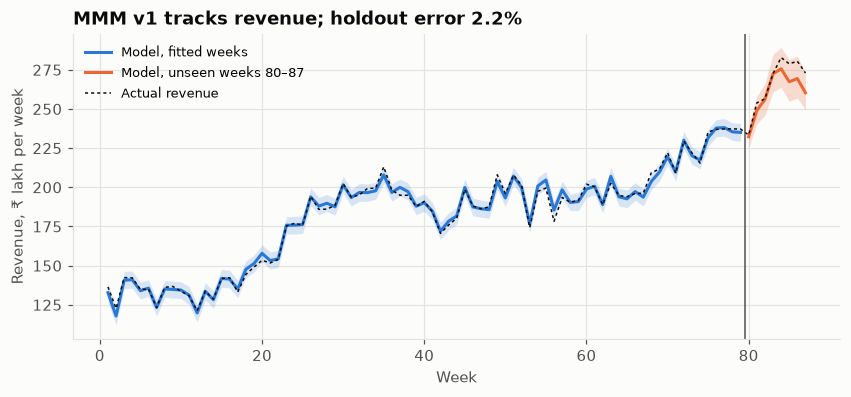

In [4]:
pp_in = mmm.sample_posterior_predictive(df[train], extend_idata=False, progressbar=False)
pp_out = mmm.sample_posterior_predictive(df[test], include_last_observations=True, extend_idata=False,
                                         progressbar=False)

def to_rupees(pp):
    var = "y_original_scale" if "y_original_scale" in pp else "y"
    arr = pp[var]
    other = [d for d in arr.dims if d not in ("date",)]
    m = arr.mean(other).values
    lo, hi = arr.quantile(0.05, other).values, arr.quantile(0.95, other).values
    scale = 1.0 if var == "y_original_scale" or m.mean() > 5 else float(mmm.idata.constant_data["target_scale"])
    return m * scale, lo * scale, hi * scale

fit_m, fit_lo, fit_hi = to_rupees(pp_in)
out_m, out_lo, out_hi = to_rupees(pp_out)
mape_hold = float(np.mean(np.abs(out_m - y[test].values) / y[test].values))
mape_in = float(np.mean(np.abs(fit_m - y[train].values) / y[train].values))
cover = float(np.mean((y[test].values >= out_lo) & (y[test].values <= out_hi)))
print(f"In-sample MAPE: {mape_in:.1%}   |   Holdout MAPE (weeks 80–87): {mape_hold:.1%}   "
      f"|   holdout weeks inside 90% band: {cover:.0%}")

fig, ax = plt.subplots(figsize=(9, 3.6))
wk = nat["week"].values
ax.fill_between(wk[train], fit_lo, fit_hi, color="#2a78d6", alpha=0.18, lw=0)
ax.fill_between(wk[test], out_lo, out_hi, color="#eb6834", alpha=0.22, lw=0)
ax.plot(wk[train], fit_m, color="#2a78d6", label="Model, fitted weeks")
ax.plot(wk[test], out_m, color="#eb6834", label="Model, unseen weeks 80–87")
ax.plot(wk, y.values, color=INK, lw=1, ls=(0, (2, 2)), label="Actual revenue")
ax.axvline(79.5, color=INK2, lw=1)
ax.set_xlabel("Week"); ax.set_ylabel("Revenue, ₹ lakh per week")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax.set_title(f"MMM v1 tracks revenue; holdout error {mape_hold:.1%}")
save(fig, "02B_fit_and_holdout"); plt.show()

## 4. Rebuild each channel's effect from the model, draw by draw
We recompute adstock + Hill ourselves from the posterior samples. This lets us ask "what if spend
were different?" cheaply, for ROI, marginal ROI and response curves. Check: the rebuilt effect
must match the model's own channel contribution.

In [5]:
cd = mmm.idata.constant_data
target_scale = float(cd["target_scale"])
ch_scale = cd["channel_scale"].to_series().reindex(CHANNELS).values
L_MAX = 24

def stack(name):
    return post[name].stack(sample=("chain", "draw")).transpose("sample", ...).values

alpha, kappa = stack("adstock_alpha"), stack("saturation_kappa")
slope, beta = stack("saturation_slope"), stack("saturation_beta")
X_train = df.loc[train, CHANNELS].values                 # weeks x channels (₹ lakh)

def contribution(X, ci, mult=1.0, weeks_mask=None):
    """Weekly contribution of channel ci (₹ lakh), per posterior draw: shape (draws, weeks)."""
    x = X[:, ci].copy()
    if weeks_mask is not None:
        x[weeks_mask] *= mult
    else:
        x *= mult
    xs = x / ch_scale[ci]
    a = alpha[:, ci][:, None] ** np.arange(L_MAX)[None, :]
    a = a / a.sum(1, keepdims=True)
    T = len(xs)
    ad = np.zeros((len(alpha), T))
    for lag in range(L_MAX):
        ad[:, lag:] += a[:, [lag]] * xs[None, :T - lag]
    s, k = slope[:, ci][:, None], kappa[:, ci][:, None]
    h = ad**s / (ad**s + k**s)
    return beta[:, ci][:, None] * h * target_scale

model_contrib = post["channel_contribution"].stack(sample=("chain", "draw")).transpose("sample", "date", "channel")
check = max(abs(contribution(X_train, i).mean(0).sum() - float(model_contrib.isel(channel=i).mean("sample").sum()) * target_scale)
            / (float(model_contrib.isel(channel=i).mean("sample").sum()) * target_scale) for i in range(len(CHANNELS)))
print(f"Rebuild check, worst channel gap vs model: {check:.2%}")

Rebuild check, worst channel gap vs model: 0.00%


## 5. ROI and marginal ROI by channel
- **ROI:** incremental revenue ÷ spend over weeks 1–79 (average return).
- **Marginal ROI (mROI):** extra revenue from the *next* ₹1, measured by raising the last 26 weeks'
  spend by 1%. This is the number a budget cut should use.

In [6]:
spend_tot = X_train.sum(0)
recent = np.zeros(len(X_train), bool); recent[-26:] = True
rows = []
for i, c in enumerate(CHANNELS):
    base = contribution(X_train, i)
    roi = base.sum(1) / spend_tot[i]
    bumped = contribution(X_train, i, 1.01, recent)
    mroi = (bumped - base).sum(1) / (0.01 * X_train[recent, i].sum())
    rows.append(dict(channel=LABEL[c], key=c, roi=np.median(roi), roi_lo=np.quantile(roi, .05), roi_hi=np.quantile(roi, .95),
                     mroi=np.median(mroi), mroi_lo=np.quantile(mroi, .05), mroi_hi=np.quantile(mroi, .95),
                     contribution_cr=np.median(base.sum(1)) / 100, spend_cr=spend_tot[i] / 100))
roi_tbl = pd.DataFrame(rows).set_index("channel")
# Trade promotions: net out the post-promotion dip the model found (pull-forward)
cc = post["control_contribution"].stack(sample=("chain", "draw")).transpose("sample", ...)
dip = cc.sel(control="post_promo").sum("date").values * target_scale          # ₹ lakh, per draw (negative = dip)
ti = CHANNELS.index("trade_promo")
gross = contribution(X_train, ti).sum(1)
net_roi = (gross + dip) / spend_tot[ti]
print(f"Post-promotion dip found by the model: ₹{np.median(dip)/100:.2f} Cr over weeks 1–79 "
      f"(90%: {np.quantile(dip,.05)/100:.2f} to {np.quantile(dip,.95)/100:.2f})")
roi_tbl.loc["Trade promotions", ["roi_gross_before_dip"]] = np.median(gross / spend_tot[ti])
roi_tbl.loc["Trade promotions", ["roi", "roi_lo", "roi_hi"]] = [np.median(net_roi), np.quantile(net_roi, .05), np.quantile(net_roi, .95)]
roi_tbl.loc["Trade promotions", "contribution_cr"] = np.median(gross + dip) / 100
plat = (p[p.week <= 79].groupby("channel").apply(lambda d: d.reported_revenue_lakh.sum() / d.spend_lakh.sum(), include_groups=False))
roi_tbl["platform_roas"] = roi_tbl["key"].map(plat)
roi_tbl["interval_width"] = roi_tbl["roi_hi"] - roi_tbl["roi_lo"]
roi_tbl["rupees_uncertain_cr"] = roi_tbl["interval_width"] * roi_tbl["spend_cr"]   # how much money the uncertainty puts at risk
# How tangled are Meta and YouTube? Negative correlation between their ROI draws = the model trades one for the other.
roi_draws = {c: contribution(X_train, i).sum(1) / spend_tot[i] for i, c in enumerate(CHANNELS)}
tangle = np.corrcoef(roi_draws["meta"], roi_draws["youtube"])[0, 1]
print(f"Correlation between Meta and YouTube ROI draws: {tangle:+.2f} (strongly negative = model cannot separate them)")
roi_tbl.drop(columns="key").round(2)

Post-promotion dip found by the model: ₹0.07 Cr over weeks 1–79 (90%: -0.46 to 0.53)


Correlation between Meta and YouTube ROI draws: -0.02 (strongly negative = model cannot separate them)


,roi,roi_lo,roi_hi,mroi,mroi_lo,mroi_hi,contribution_cr,spend_cr,roi_gross_before_dip,platform_roas,interval_width,rupees_uncertain_cr
channel,,,,,,,,,,,,
Meta,0.09,0.00,1.40,0.03,0.00,0.14,0.98,10.57,NaN,7.59,1.40,14.77
Quick-commerce ads,0.71,0.14,3.49,0.41,0.09,0.82,6.33,8.86,NaN,7.54,3.35,29.67
Google Search,1.49,0.79,4.63,2.93,1.72,4.26,8.46,5.69,NaN,5.21,3.83,21.82
Trade promotions,2.72,1.41,7.03,0.91,0.71,1.07,12.73,4.68,2.72,2.74,5.62,26.29
YouTube,1.25,0.95,1.60,2.41,1.90,2.99,8.14,6.50,NaN,2.52,0.65,4.20
Influencers,1.02,0.41,2.99,1.05,0.34,2.42,4.02,3.95,NaN,4.87,2.58,10.19


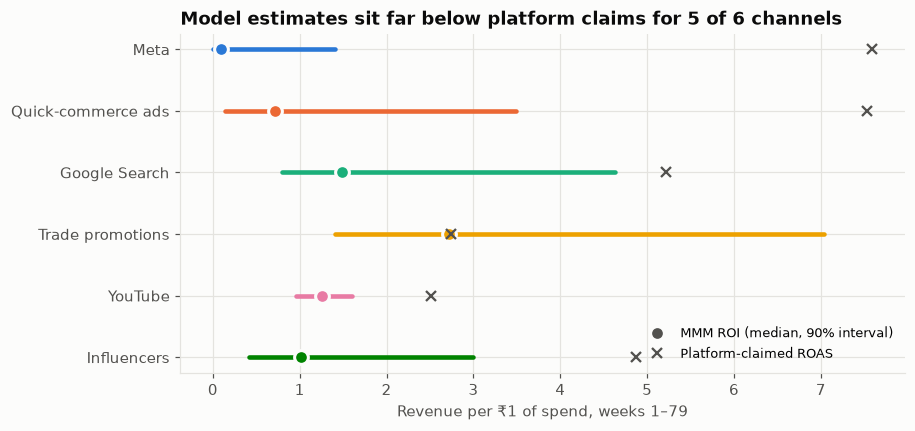

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4))
yy = np.arange(len(roi_tbl))
for j, (name, r) in enumerate(roi_tbl.iterrows()):
    ax.plot([r.roi_lo, r.roi_hi], [j, j], color=COLOR[r.key], lw=3, solid_capstyle="round")
    ax.plot(r.roi, j, "o", color=COLOR[r.key], ms=9, mec="#fcfcfb", mew=2)
    ax.plot(r.platform_roas, j, marker="x", color=INK2, ms=7, mew=1.5)
ax.plot([], [], "o", color=INK2, label="MMM ROI (median, 90% interval)")
ax.plot([], [], "x", color=INK2, ms=7, mew=1.5, label="Platform-claimed ROAS")
ax.set_yticks(yy, roi_tbl.index); ax.invert_yaxis()
ax.set_xlabel("Revenue per ₹1 of spend, weeks 1–79")
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
ax.set_title("Model estimates sit far below platform claims for 5 of 6 channels")
save(fig, "02B_roi_vs_platform"); plt.show()

## 6. Response curves: where is each channel on its tiredness curve?
Each curve shows total incremental revenue if the whole channel's spend were scaled from 0× to 2×.
The dot marks today's spend. A flat curve at the dot = saturated; steep = room to grow.

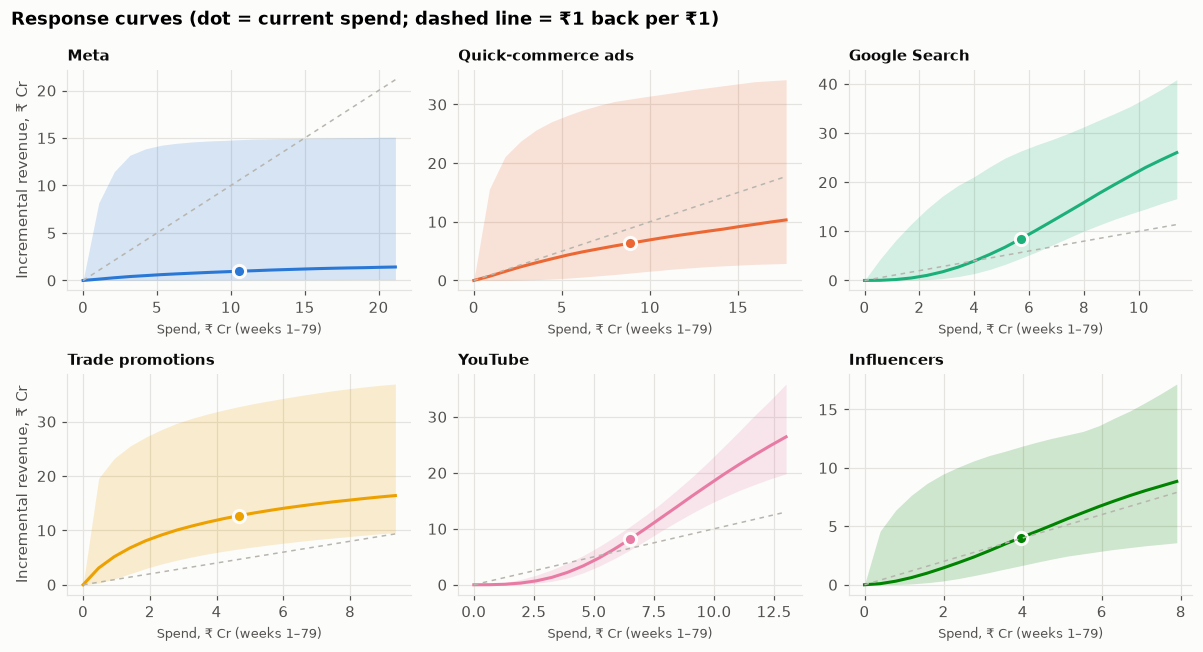

In [8]:
mults = np.linspace(0, 2, 21)
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharey=False)
curves = {}
for i, (c, ax) in enumerate(zip(CHANNELS, axes.ravel())):
    vals = np.array([contribution(X_train, i, m).sum(1) for m in mults]) / 100      # (mults, draws) ₹ Cr
    med, lo, hi = np.median(vals, 1), np.quantile(vals, .05, 1), np.quantile(vals, .95, 1)
    curves[c] = pd.DataFrame({"spend_multiple": mults, "spend_cr": mults * spend_tot[i] / 100,
                              "contribution_cr": med, "lo": lo, "hi": hi})
    xs = mults * spend_tot[i] / 100
    ax.fill_between(xs, lo, hi, color=COLOR[c], alpha=0.18, lw=0)
    ax.plot(xs, med, color=COLOR[c])
    ax.plot(spend_tot[i] / 100, np.interp(1, mults, med), "o", color=COLOR[c], ms=8, mec="#fcfcfb", mew=2)
    ax.plot(xs, xs, color=NEUTRAL, lw=1, ls=(0, (3, 3)))
    ax.set_title(LABEL[c], fontsize=10)
    ax.set_xlabel("Spend, ₹ Cr (weeks 1–79)", fontsize=8.5)
axes[0, 0].set_ylabel("Incremental revenue, ₹ Cr"); axes[1, 0].set_ylabel("Incremental revenue, ₹ Cr")
fig.suptitle("Response curves (dot = current spend; dashed line = ₹1 back per ₹1)", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "02B_response_curves"); plt.show()

## 7. Adstock: how long does each channel's effect last?

In [9]:
hl = np.log(0.5) / np.log(np.clip(alpha, 1e-6, 0.999999))
ad_tbl = pd.DataFrame({"half-life median (weeks)": np.median(hl, 0), "5%": np.quantile(hl, .05, 0),
                       "95%": np.quantile(hl, .95, 0)}, index=[LABEL[c] for c in CHANNELS])
ad_tbl.round(2)

,half-life median (weeks),5%,95%
Meta,0.42,0.17,1.38
Quick-commerce ads,0.29,0.14,0.65
Google Search,0.57,0.22,1.24
Trade promotions,0.22,0.12,0.34
YouTube,2.70,2.05,3.58
Influencers,1.06,0.31,2.63


## 8. Save outputs for later steps (optimiser, app, copilot)

In [10]:
out_dir = ROOT / "model"; out_dir.mkdir(exist_ok=True)
roi_tbl.drop(columns="key").to_csv(out_dir / "mmm_v1_roi.csv")
pd.concat({LABEL[c]: d for c, d in curves.items()}).to_csv(out_dir / "mmm_v1_response_curves.csv")
pd.DataFrame([diag]).to_csv(out_dir / "mmm_v1_diagnostics.csv", index=False)
pd.DataFrame({"alpha": [*alpha.T], }).head(0)
np.savez_compressed(out_dir / "mmm_v1_posterior_params.npz", alpha=alpha, kappa=kappa, slope=slope, beta=beta,
                    channel_scale=ch_scale, target_scale=target_scale, channels=np.array(CHANNELS))
if not QUICK:
    try:
        mmm.save(str(out_dir / "mmm_v1.nc"))   # large file: kept on Drive, not GitHub
    except Exception as e:
        print("Model file not saved (needs h5netcdf or netCDF4):", e)
print("Saved:", *sorted(p.name for p in out_dir.glob("mmm_v1*")))

Saved: mmm_v1.nc mmm_v1_diagnostics.csv mmm_v1_posterior_params.npz mmm_v1_response_curves.csv mmm_v1_roi.csv


## 9. So what (for the CFO)

In [11]:
r = roi_tbl.sort_values("roi", ascending=False)
widest = roi_tbl["rupees_uncertain_cr"].idxmax()
sat = roi_tbl.assign(gap=roi_tbl.roi - roi_tbl.mroi).sort_values("gap", ascending=False)
room = roi_tbl.sort_values("mroi", ascending=False)
print("SO WHAT")
print(f"1. Ranking by true average return: " + ", ".join(f"{n} {v:.2f}" for n, v in r.roi.items()) + " (₹ per ₹1).")
print(f"2. Most saturated (average far above marginal): {sat.index[0]} (ROI {sat.roi.iloc[0]:.2f} vs mROI {sat.mroi.iloc[0]:.2f}). "
      f"Most room to grow: {room.index[0]} (mROI {room.mroi.iloc[0]:.2f}).")
print(f"3. Most money at risk from uncertainty: {widest} (ROI 90% interval {roi_tbl.loc[widest, 'roi_lo']:.2f}–{roi_tbl.loc[widest, 'roi_hi']:.2f} "
      f"on ₹{roi_tbl.loc[widest, 'spend_cr']:.1f} Cr of spend = ₹{roi_tbl.loc[widest, 'rupees_uncertain_cr']:.1f} Cr uncertain). "
      f"Candidate for the geo experiment (Stage D).")
print(f"4. Meta vs YouTube: ROI draws correlate {tangle:+.2f}, so " +
      ("the model trades credit between them." if tangle < -0.3 else
       "the model separates them despite the 0.90 spend correlation; whether it splits them correctly is tested at grading."))
print(f"5. Trust: diagnostics {'PASS' if diag['PASS'] else 'FAIL'}; holdout error {mape_hold:.1%} (OLS: 4.6%).")

SO WHAT
1. Ranking by true average return: Trade promotions 2.72, Google Search 1.49, YouTube 1.25, Influencers 1.02, Quick-commerce ads 0.71, Meta 0.09 (₹ per ₹1).
2. Most saturated (average far above marginal): Trade promotions (ROI 2.72 vs mROI 0.91). Most room to grow: Google Search (mROI 2.93).
3. Most money at risk from uncertainty: Quick-commerce ads (ROI 90% interval 0.14–3.49 on ₹8.9 Cr of spend = ₹29.7 Cr uncertain). Candidate for the geo experiment (Stage D).
4. Meta vs YouTube: ROI draws correlate -0.02, so the model separates them despite the 0.90 spend correlation; whether it splits them correctly is tested at grading.
5. Trust: diagnostics PASS; holdout error 2.2% (OLS: 4.6%).
